In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_ag = pd.read_csv("processed_df.csv")
df_ag = df_ag[df_ag['AGENTE_TOX'].isin([2.0, 3.0, 4.0])]
display(df_ag)

/tmp/ipykernel_8382/3127311658.py:5: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ag = pd.read_csv("processed_df.csv")


,DT_NOTIFIC,ID_OCUPA_N,SIT_TRAB,LOC_EXPO,ID_MUNICIP,UF_EMP,MUN_EMP,AGENTE_TOX,VIA_1,CIRCUNSTAN,...,LOC_EXPO_DESC,AGENTE_TOX_DESC,VIA_1_DESC,CIRCUNSTAN_DESC,TPEXP_DESC,SIT_TRAB_DESC,CLASSI_FIN_DESC,EVOLUCAO_DESC,IDADE_ANOS,INTERNADO
16,2013-04-27,21210.0,4.0,1.0,230440,23.0,230765.0,2.0,1.0,10.0,...,Residência,Agrotóxico (Uso Agrícola),Digestiva,Tentativa de suicídio,Aguda-única,Servidor público estatutário,Confirmado,Cura sem sequela,50.0,0
34,2013-04-27,NaN,99.0,1.0,411520,41.0,410170.0,3.0,1.0,10.0,...,Residência,Agrotóxico (Uso Doméstico),Digestiva,Tentativa de suicídio,Aguda-única,Ignorado,Confirmado,Perda de seguimento,12.0,0
48,2013-04-28,NaN,12.0,1.0,110004,11.0,110150.0,2.0,1.0,2.0,...,Residência,Agrotóxico (Uso Agrícola),Digestiva,Acidental,Aguda-única,Outros,Exposição,Cura sem sequela,1.0,1
52,2013-04-28,621005.0,3.0,6.0,320140,32.0,320140.0,2.0,1.0,10.0,...,Unidade de saúde,Agrotóxico (Uso Agrícola),Digestiva,Tentativa de suicídio,Aguda-repetida,Autônomo/conta própria,Confirmado,Cura sem sequela,29.0,1
77,2013-04-28,999991.0,99.0,1.0,411150,41.0,412250.0,2.0,5.0,10.0,...,Residência,Agrotóxico (Uso Agrícola),Parenteral,Tentativa de suicídio,Aguda-única,Ignorado,Confirmado,Cura sem sequela,17.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1193198,2023-10-03,999992,99.0,1.0,521975,52.0,521975.0,3.0,1.0,2.0,...,Residência,Agrotóxico (Uso Doméstico),Digestiva,Acidental,Aguda-única,Ignorado,Exposição,Cura sem sequela,3.0,0
1193223,2023-10-03,752305,6.0,1.0,420940,42.0,420940.0,3.0,1.0,2.0,...,Residência,Agrotóxico (Uso Doméstico),Digestiva,Acidental,Aguda-única,Aposentado,Diagnóstico Diferencial,Cura sem sequela,64.0,0
1193273,2023-10-03,621005,3.0,1.0,230330,23.0,230330.0,2.0,1.0,10.0,...,Residência,Agrotóxico (Uso Agrícola),Digestiva,Tentativa de suicídio,Aguda-única,Autônomo/conta própria,Confirmado,Cura sem sequela,54.0,1
1193274,2023-10-03,612005,2.0,2.0,230423,23.0,230423.0,2.0,1.0,1.0,...,Habitação coletiva,Agrotóxico (Uso Agrícola),Digestiva,Uso habitual,Aguda-repetida,Empregado sem carteira,Exposição,Cura sem sequela,29.0,0


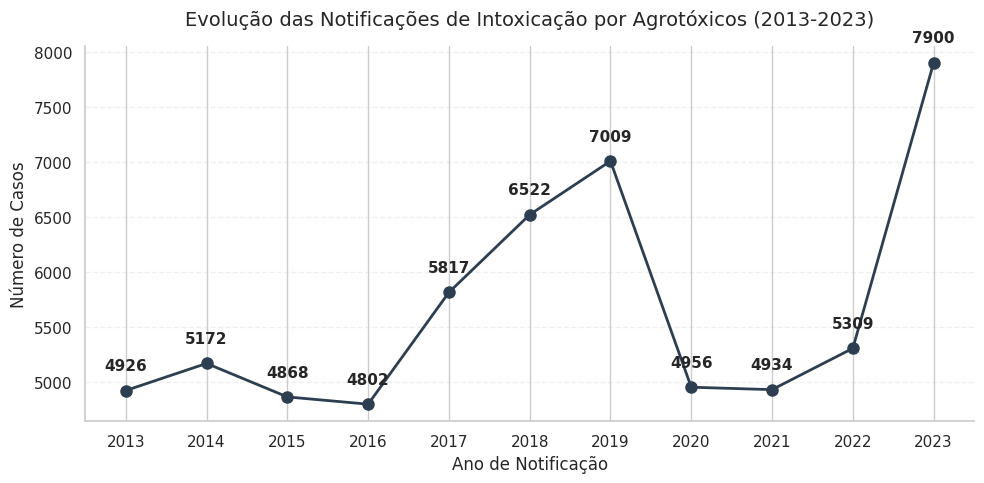

In [31]:
# Extração da data
df_ag['DT_NOTIFIC'] = pd.to_datetime(df_ag['DT_NOTIFIC'], errors='coerce')
contagem_anos = df_ag['DT_NOTIFIC'].dt.year.value_counts().sort_index()

# Configuração da figura
plt.figure(figsize=(10, 5))
contagem_anos.plot(kind='line', marker='o', color='#2c3e50', lw=2, markersize=8)

# Títulos e rótulos
plt.title('Evolução das Notificações de Intoxicação por Agrotóxicos (2013-2023)', fontsize=14, pad=15)
plt.xlabel('Ano de Notificação', fontsize=12)
plt.ylabel('Número de Casos', fontsize=12)

# Força o eixo X a mostrar apenas os anos
plt.xticks(contagem_anos.index)

# Adiciona os números em cima de cada ponto do gráfico
for ano, valor in zip(contagem_anos.index, contagem_anos.values):
    plt.text(ano, valor + (max(contagem_anos.values) * 0.02), f'{int(valor)}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

# Estética limpa
plt.grid(axis='y', alpha=0.3, linestyle='--')
sns.despine()
plt.tight_layout()

# plt.savefig('evolucao_notific_21_23.png', dpi=300, bbox_inches='tight')

plt.show()

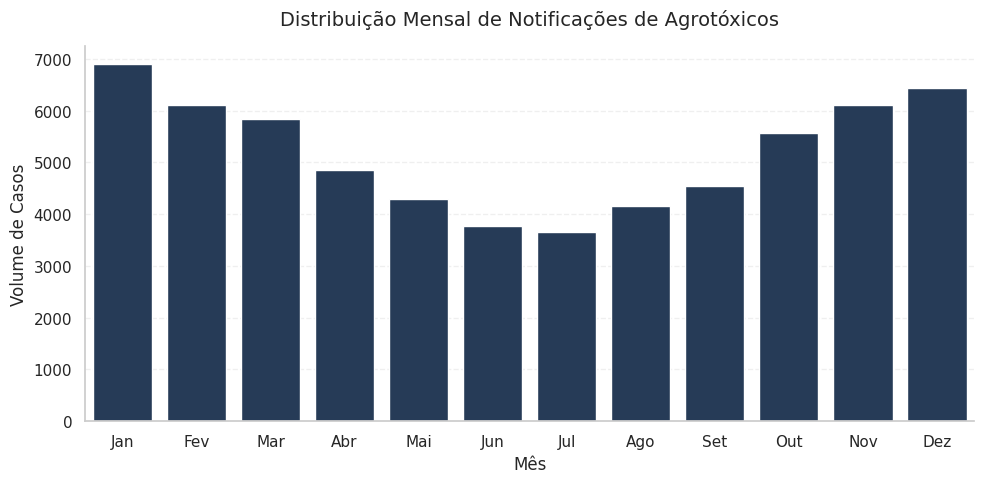

In [32]:
# Criando a coluna auxiliar de Mês
df_ag['Mes'] = df_ag['DT_NOTIFIC'].dt.month

# Configurando o tamanho da figura para 1 único gráfico (mais estreito que o original)
plt.figure(figsize=(10, 5))

# Calculando os casos por mês
casos_mes = df_ag['Mes'].value_counts().sort_index()

# Plotando o gráfico de barras
sns.barplot(
    x=casos_mes.index,
    y=casos_mes.values,
    color="#1E3A5F",
    legend=False
)

# Ajustando títulos e rótulos
plt.title('Distribuição Mensal de Notificações de Agrotóxicos', fontsize=14, pad=15)
plt.ylabel('Volume de Casos', fontsize=12)
plt.xlabel('Mês', fontsize=12)

# Trocando os números 1 a 12 pelos nomes dos meses formatados
plt.xticks(
    ticks=range(12),
    labels=['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
)

# Deixando a estética mais limpa e profissional
sns.despine()
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()

# Salvando a imagem com um nome que faz sentido agora
#plt.savefig('sazonalidade_mensal.png', dpi=300, bbox_inches='tight')

plt.show()

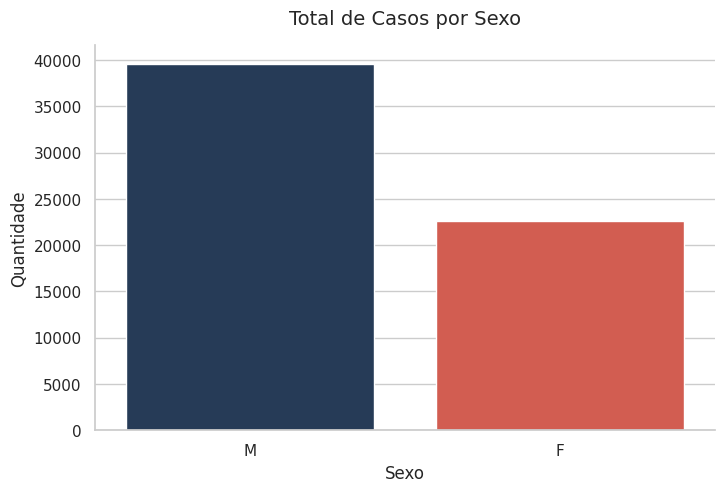

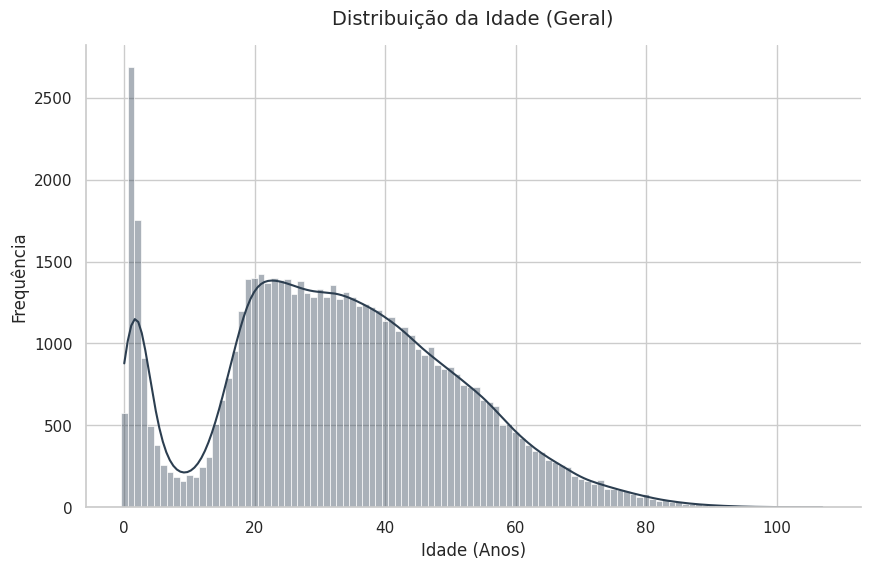

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtra apenas os sexos M e F (caso ainda não tenha feito)
df_sexo = df_ag[df_ag['CS_SEXO'].isin(['M', 'F'])]

# --- PLOT 1: DISTRIBUIÇÃO POR SEXO ---
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df_sexo,
    x='CS_SEXO',
    palette={'M': '#1E3A5F', 'F': '#e74c3c'},
    hue='CS_SEXO',
    legend=False
)

plt.title('Total de Casos por Sexo', fontsize=14, pad=15)
plt.xlabel('Sexo', fontsize=12)
plt.ylabel('Quantidade', fontsize=12)
sns.despine()
plt.show()

# --- PLOT 2: DISTRIBUIÇÃO POR IDADE ---
plt.figure(figsize=(10, 6))
sns.histplot(
    data=df_sexo,
    x='IDADE_ANOS',
    kde=True,
    discrete=True,  # <--- Isso força 1 barra por cada ano inteiro
    color='#2c3e50',
    alpha=0.4
)

plt.title('Distribuição da Idade (Geral)', fontsize=14, pad=15)
plt.xlabel('Idade (Anos)', fontsize=12)
plt.ylabel('Frequência', fontsize=12)
sns.despine()
plt.show()

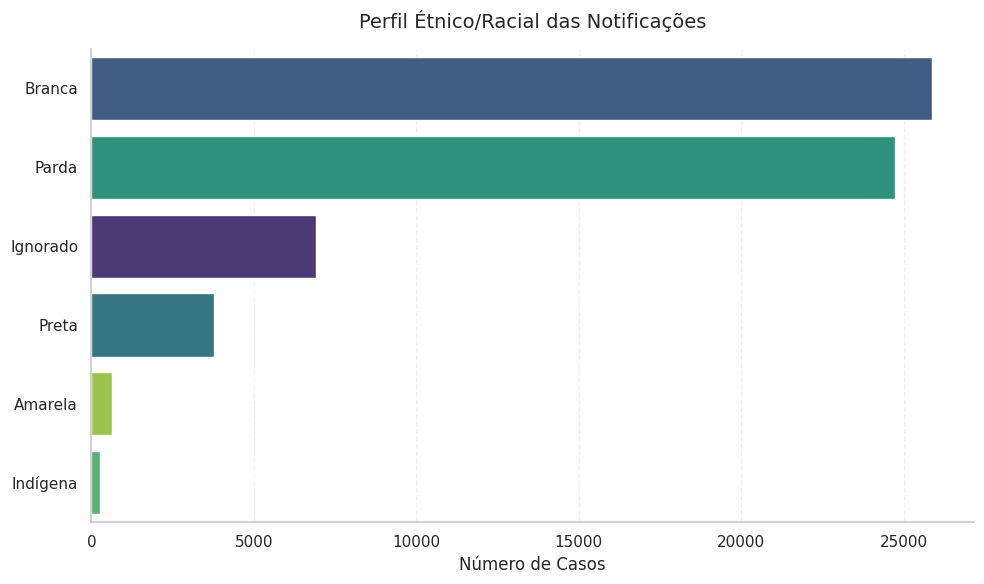

In [34]:
plt.figure(figsize=(10, 6))

# Calcula a ordem das categorias da maior para a menor
ordem_raca = df_ag['CS_RACA_DESC'].value_counts().index

# Plotagem das barras horizontais (hue adicionado para evitar warnings)
sns.countplot(
    data=df_ag,
    y='CS_RACA_DESC',
    order=ordem_raca,
    hue='CS_RACA_DESC',
    palette='viridis',
    legend=False
)

# Estética e rótulos
plt.title('Perfil Étnico/Racial das Notificações', fontsize=14, pad=15)
plt.xlabel('Número de Casos', fontsize=12)
plt.ylabel('', fontsize=12) # Deixei vazio pois os nomes das raças já explicam o eixo

# Adicionando um grid vertical suave para facilitar a leitura dos números
plt.grid(axis='x', alpha=0.3, linestyle='--')
sns.despine()
plt.tight_layout()

# Salvando a imagem individual
#plt.savefig('perfil_etnico.png', dpi=300, bbox_inches='tight')

plt.show()

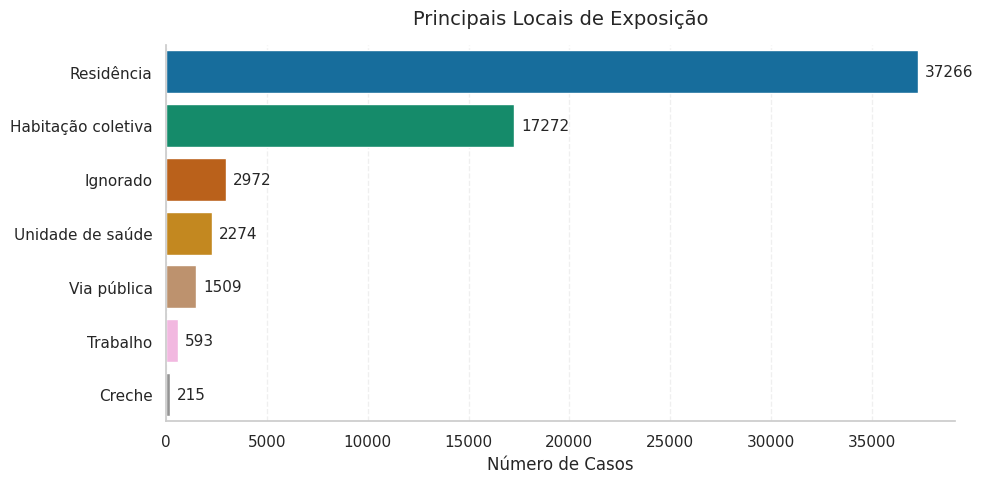

In [35]:
plt.figure(figsize=(10, 5))

ordem_local = df_ag['LOC_EXPO_DESC'].value_counts().head(7).index

ax = sns.countplot(
    data=df_ag,
    y='LOC_EXPO_DESC',
    order=ordem_local,
    hue='LOC_EXPO_DESC',
    palette='colorblind',
    legend=False
)

plt.title('Principais Locais de Exposição', fontsize=14, pad=15)
plt.xlabel('Número de Casos', fontsize=12)
plt.ylabel('', fontsize=12)

# Adiciona os números no final de cada barra de forma limpa
for i in ax.containers:
    ax.bar_label(i, padding=5, fmt='%d', fontsize=11)

sns.despine()
plt.grid(axis='x', alpha=0.3, linestyle='--')
plt.tight_layout()

#plt.savefig('locais_exposicao.png', dpi=300, bbox_inches='tight')
plt.show()

<Figure size 1400x600 with 0 Axes>

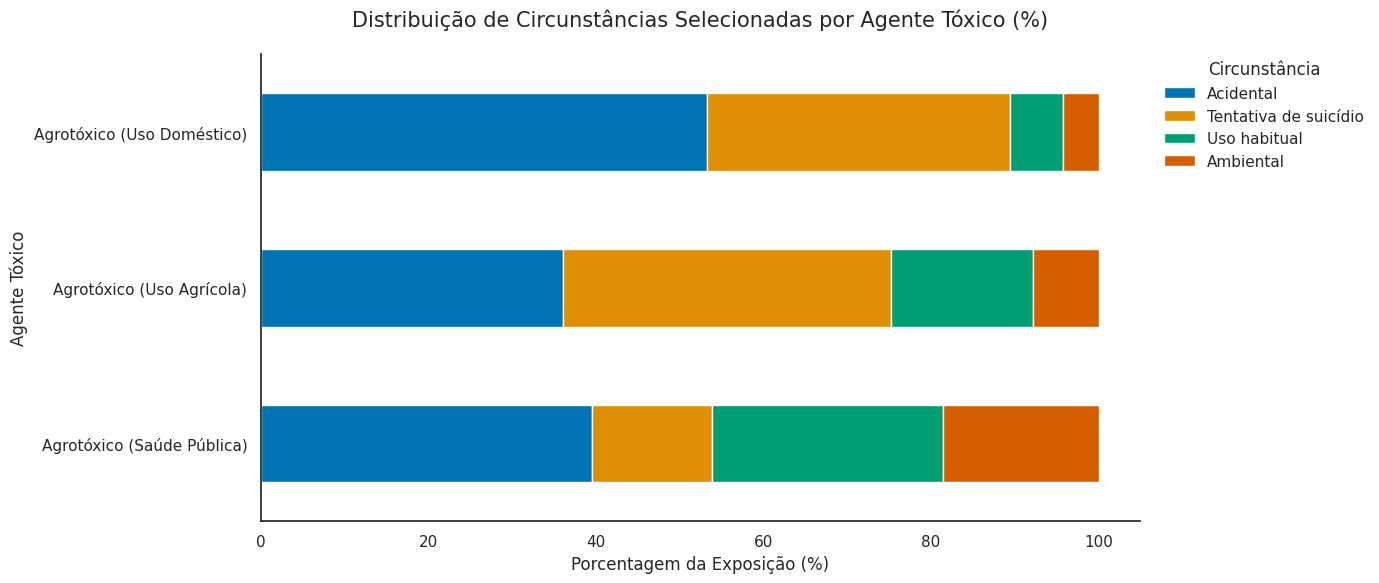

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Filtramos o dataframe para conter apenas as 4 circunstâncias desejadas
alvos = ['Acidental', 'Tentativa de suicídio', 'Uso habitual', 'Ambiental']
df_filtrado = df_ag[df_ag['CIRCUNSTAN_DESC'].isin(alvos)].copy()

# 2. Geramos o crosstab usando o dataframe já filtrado
crosstab_agente_circ = pd.crosstab(
    df_filtrado['AGENTE_TOX_DESC'],
    df_filtrado['CIRCUNSTAN_DESC'],
    normalize='index'
) * 100

crosstab_agente_circ = crosstab_agente_circ.reindex(columns=alvos)

# --- Configuração do Gráfico ---
plt.figure(figsize=(14, 6))
sns.set_theme(style="white")

# Usamos a paleta colorblind para melhor acessibilidade
colors = sns.color_palette("colorblind", len(crosstab_agente_circ.columns))

# Criando o plot
ax = crosstab_agente_circ.plot(
    kind='barh',
    stacked=True,
    figsize=(14, 6),
    color=colors,
    edgecolor='white'
)

# Estética e Rótulos
plt.title('Distribuição de Circunstâncias Selecionadas por Agente Tóxico (%)', fontsize=15, pad=20)
plt.xlabel('Porcentagem da Exposição (%)', fontsize=12)
plt.ylabel('Agente Tóxico', fontsize=12)

# Legenda externa à direita
plt.legend(
    title='Circunstância',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    borderaxespad=0,
    frameon=False
)

plt.yticks(fontsize=11)
sns.despine()
plt.tight_layout()

plt.show()

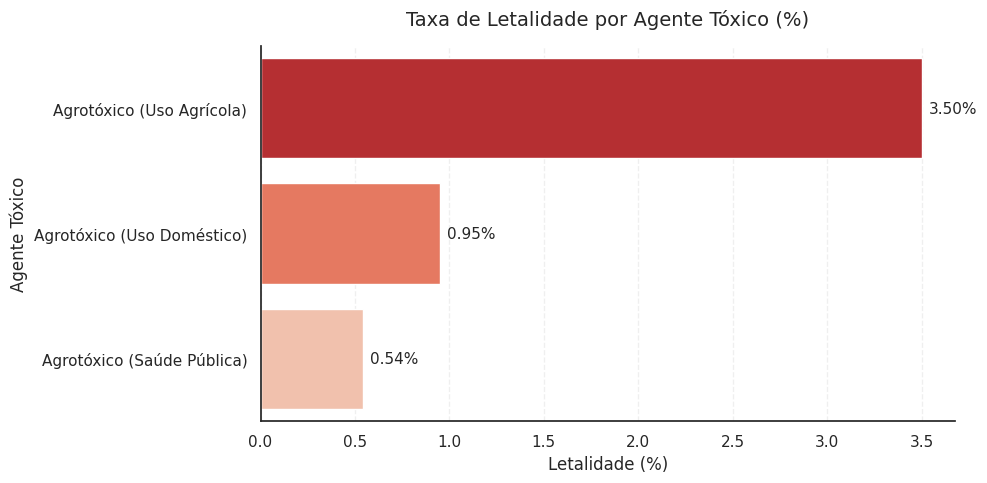

In [37]:
total_agente = df_ag['AGENTE_TOX_DESC'].value_counts()
obitos_agente = df_ag[df_ag['EVOLUCAO_DESC'] == 'Óbito por Intoxicação Exógena']['AGENTE_TOX_DESC'].value_counts()

# Calcula a porcentagem, preenche nulos com 0 e pega os 8 mais letais
taxa_letalidade = (obitos_agente / total_agente * 100).fillna(0).sort_values(ascending=False).head(8)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=taxa_letalidade.values,
    y=taxa_letalidade.index,
    hue=taxa_letalidade.index,
    palette='Reds_r',
    legend=False
)

plt.title('Taxa de Letalidade por Agente Tóxico (%)', fontsize=14, pad=15)
plt.xlabel('Letalidade (%)', fontsize=12)
plt.ylabel('Agente Tóxico', fontsize=12)

for i in ax.containers:
    ax.bar_label(i, fmt='%.2f%%', padding=5, fontsize=11)

sns.despine()
plt.grid(axis='x', alpha=0.3, linestyle='--')
plt.tight_layout()

#plt.savefig('taxa_letalidade_agente.png', dpi=300, bbox_inches='tight')
plt.show()

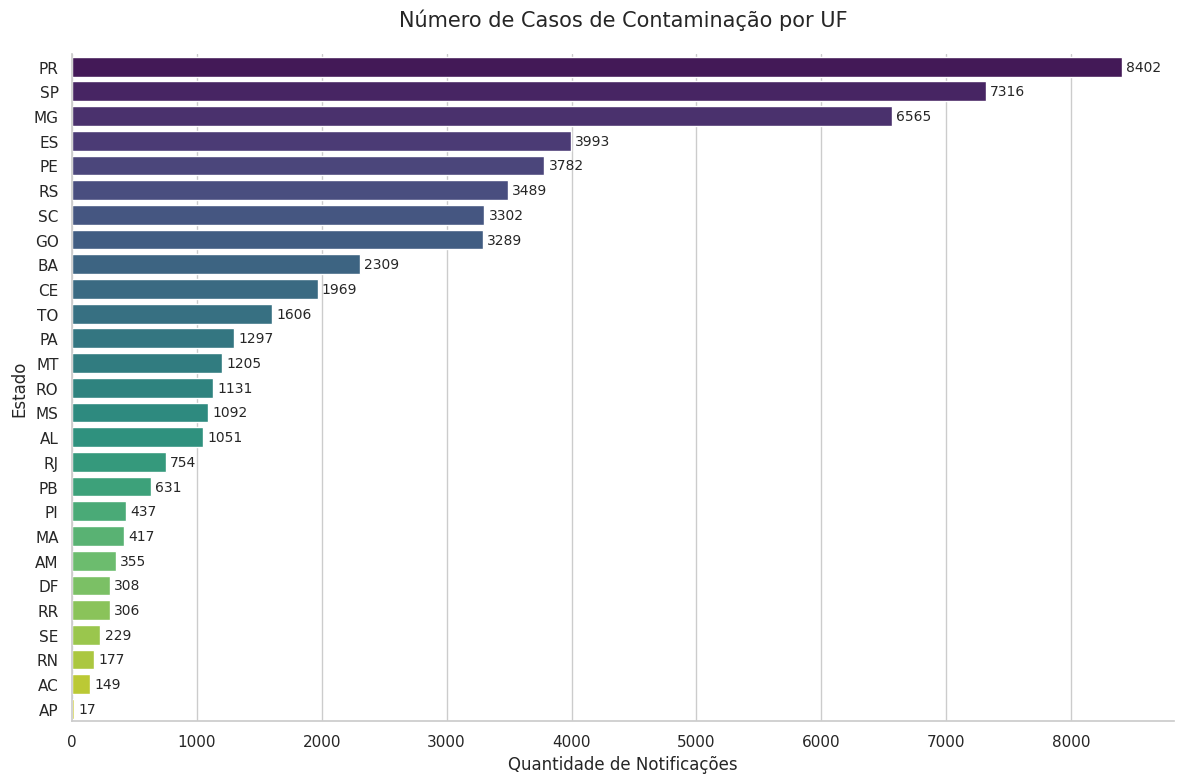

In [38]:
# Mapeamento oficial do IBGE para as Unidades da Federação
dic_uf = {
    11: 'RO', 12: 'AC', 13: 'AM', 14: 'RR', 15: 'PA', 16: 'AP', 17: 'TO',
    21: 'MA', 22: 'PI', 23: 'CE', 24: 'RN', 25: 'PB', 26: 'PE', 27: 'AL', 28: 'SE', 29: 'BA',
    31: 'MG', 32: 'ES', 33: 'RJ', 35: 'SP',
    41: 'PR', 42: 'SC', 43: 'RS',
    50: 'MS', 51: 'MT', 52: 'GO', 53: 'DF'
}

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Converte a coluna para inteiro (caso esteja como float ou string) e mapeia
# Usamos errors='ignore' ou fillna para tratar códigos que não estejam no dicionário
df_ag['UF_NOME'] = df_ag['UF_EMP'].astype(float).fillna(0).astype(int).map(dic_uf)

# 2. Calcula a frequência e ordena do maior para o menor
contagem_uf = df_ag['UF_NOME'].value_counts().reset_index()
contagem_uf.columns = ['Estado', 'Casos']

# 3. Criação do Gráfico
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=contagem_uf,
    x='Casos',
    y='Estado',
    palette='viridis',
    hue='Estado',
    legend=False
)

# Adiciona os valores nas pontas das barras para facilitar a leitura
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)

plt.title('Número de Casos de Contaminação por UF', fontsize=15, pad=20)
plt.xlabel('Quantidade de Notificações', fontsize=12)
plt.ylabel('Estado', fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()

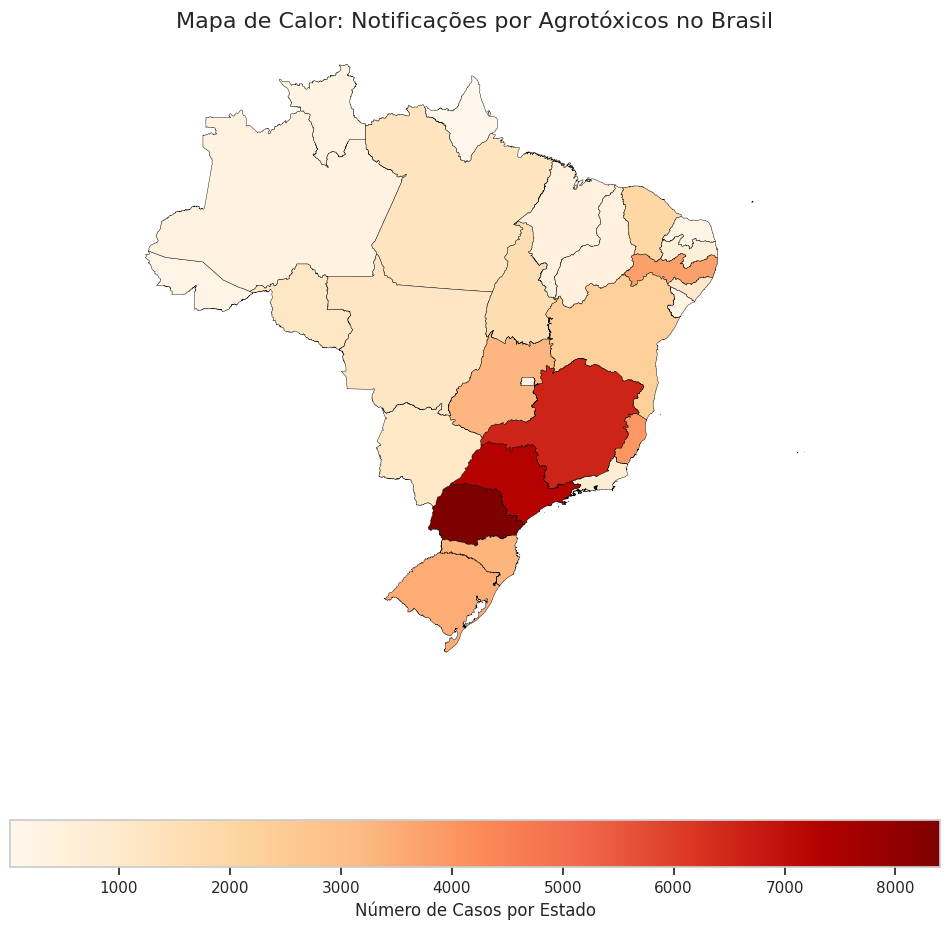

In [39]:
import geopandas as gpd
import geobr
import matplotlib.pyplot as plt

# 1. Baixa os mapas das UFs do Brasil (IBGE)
mapa_brasil = geobr.read_state(year=2020)

# 2. Une os dados de contaminação com o mapa
# 'abbrev_state' é a coluna de siglas no geobr
df_mapa = mapa_brasil.merge(contagem_uf, left_on='abbrev_state', right_on='Estado')

# 3. Plotagem
fig, ax = plt.subplots(1, 1, figsize=(12, 12))
df_mapa.plot(
    column='Casos',
    cmap='OrRd',
    legend=True,
    legend_kwds={'label': "Número de Casos por Estado", 'orientation': "horizontal"},
    ax=ax,
    edgecolor='black',
    linewidth=0.3
)

ax.set_title('Mapa de Calor: Notificações por Agrotóxicos no Brasil', fontsize=16)
ax.axis('off') # Remove as coordenadas de latitude/longitude
plt.show()

In [40]:
import geobr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Baixa a lista de todos os municípios brasileiros (metadados)
mun_metadata = geobr.read_municipality(year=2020)

# 2. Cria o "Dicionário" a partir do Geodataframe
# O SINAN usa códigos de 6 dígitos, o IBGE usa 7.
# Vamos garantir que os códigos batam convertendo para string e pegando os 6 primeiros dígitos.
mun_metadata['code_muni_6'] = mun_metadata['code_muni'].astype(str).str[:6]
dic_municipios = dict(zip(mun_metadata['code_muni_6'], mun_metadata['name_muni']))

# 3. Processa sua coluna original (ID_MUNICIP)
# Garantimos que seja string e tenha 6 caracteres (preenchendo com zeros à esquerda se necessário)
df_ag['ID_MUNICIP_STR'] = df_ag['ID_MUNICIP'].astype(float).fillna(0).astype(int).astype(str).str.zfill(6)
df_ag['NOME_MUNICIPIO'] = df_ag['ID_MUNICIP_STR'].map(dic_municipios)

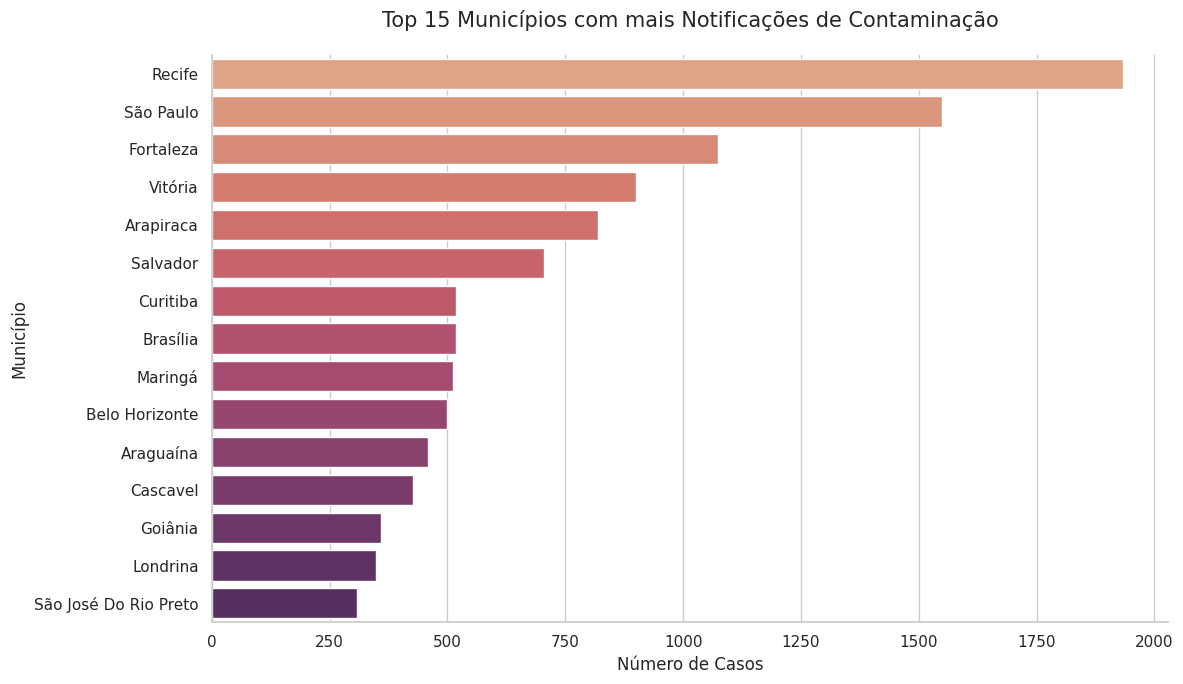

In [41]:
# Calcula o Top 15
top_municipios = df_ag['NOME_MUNICIPIO'].value_counts().head(15).reset_index()
top_municipios.columns = ['Município', 'Casos']

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_municipios,
    x='Casos',
    y='Município',
    palette='flare',
    hue='Município',
    legend=False
)

plt.title('Top 15 Municípios com mais Notificações de Contaminação', fontsize=15, pad=20)
plt.xlabel('Número de Casos', fontsize=12)
plt.ylabel('Município', fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()

In [42]:
import requests

# URL da API do IBGE (Censo 2022 - População residente por município)
url_ibge = "https://servicodados.ibge.gov.br/api/v3/agregados/4709/periodos/2022/variaveis/93?localidades=N6[all]"

print("Baixando dados de população do IBGE...")
response = requests.get(url_ibge)
data = response.json()

# O JSON do IBGE é aninhado, vamos extrair as informações:
resultados = data[0]['resultados'][0]['series']

linhas = []
for item in resultados:
    cod_ibge = item['localidade']['id']
    populacao = item['serie']['2022']
    linhas.append({
        'ID_IBGE_7': str(cod_ibge),
        'Populacao': int(populacao)
    })

df_populacao = pd.DataFrame(linhas)

# pegando apenas os 6 primeiros digitos pq o sinan é diferente do ibge
df_populacao['ID_MUNICIP'] = df_populacao['ID_IBGE_7'].str[:6].astype(float)

print("Dados do IBGE carregados com sucesso!")
display(df_populacao.head())

Baixando dados de população do IBGE...
Dados do IBGE carregados com sucesso!


,ID_IBGE_7,Populacao,ID_MUNICIP
0,1100015,21494,110001.0
1,1100023,96833,110002.0
2,1100031,5351,110003.0
3,1100049,86887,110004.0
4,1100056,15890,110005.0


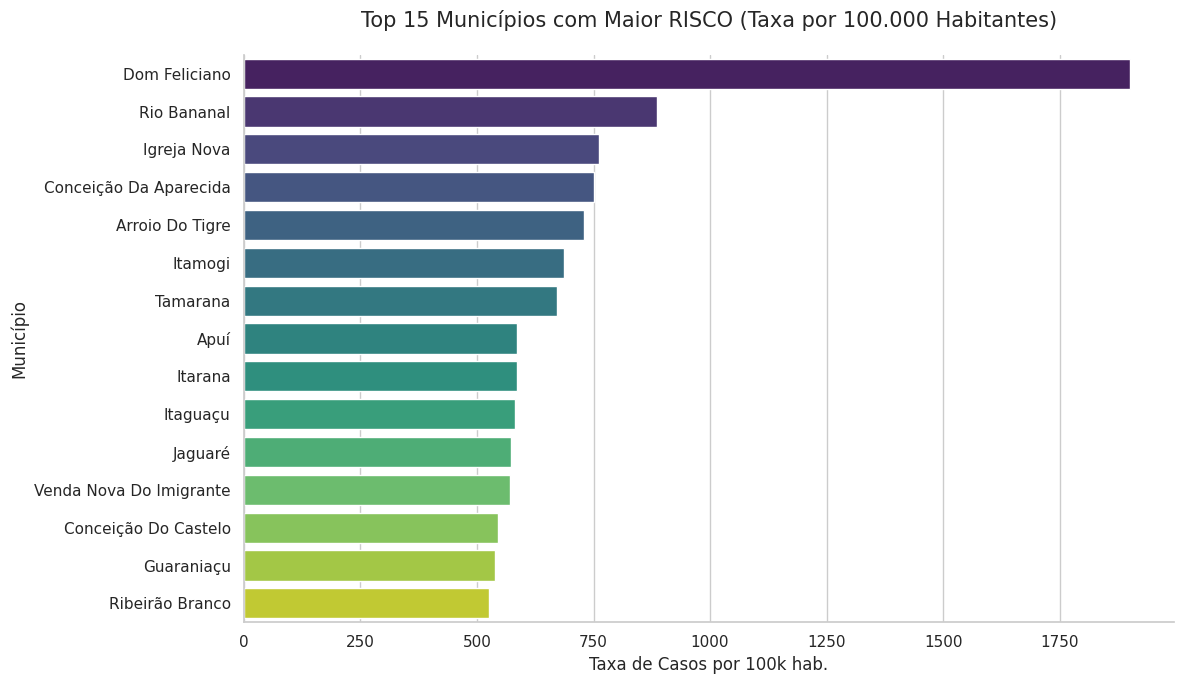

In [43]:
# 1. Agrupar os casos absolutos por ID e NOME do município no seu dataset original
df_casos = df_ag.groupby(['ID_MUNICIP', 'NOME_MUNICIPIO']).size().reset_index(name='Casos')

# 2. Cruzar (Merge) os casos com os dados de população usando o código de 6 dígitos
df_taxa = pd.merge(df_casos, df_populacao, on='ID_MUNICIP', how='inner')

# 3. Calcular a Taxa por 100 mil habitantes
df_taxa['Taxa_100k'] = (df_taxa['Casos'] / df_taxa['Populacao']) * 100000

# 4. Pegando o Top 15 com as MAIORES TAXAS
# filtrando para cidades com pelo menos 10.000 habitantes para ter dados mais sólidos:
df_taxa_filtrada = df_taxa[df_taxa['Populacao'] >= 10000]
top_taxas = df_taxa_filtrada.sort_values(by='Taxa_100k', ascending=False).head(15)

# 5. Plotar o novo gráfico "Depois"
plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_taxas,
    x='Taxa_100k',
    y='NOME_MUNICIPIO',
    palette='viridis',
    hue='NOME_MUNICIPIO',
    legend=False
)

plt.title('Top 15 Municípios com Maior RISCO (Taxa por 100.000 Habitantes)', fontsize=15, pad=20)
plt.xlabel('Taxa de Casos por 100k hab.', fontsize=12)
plt.ylabel('Município', fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()

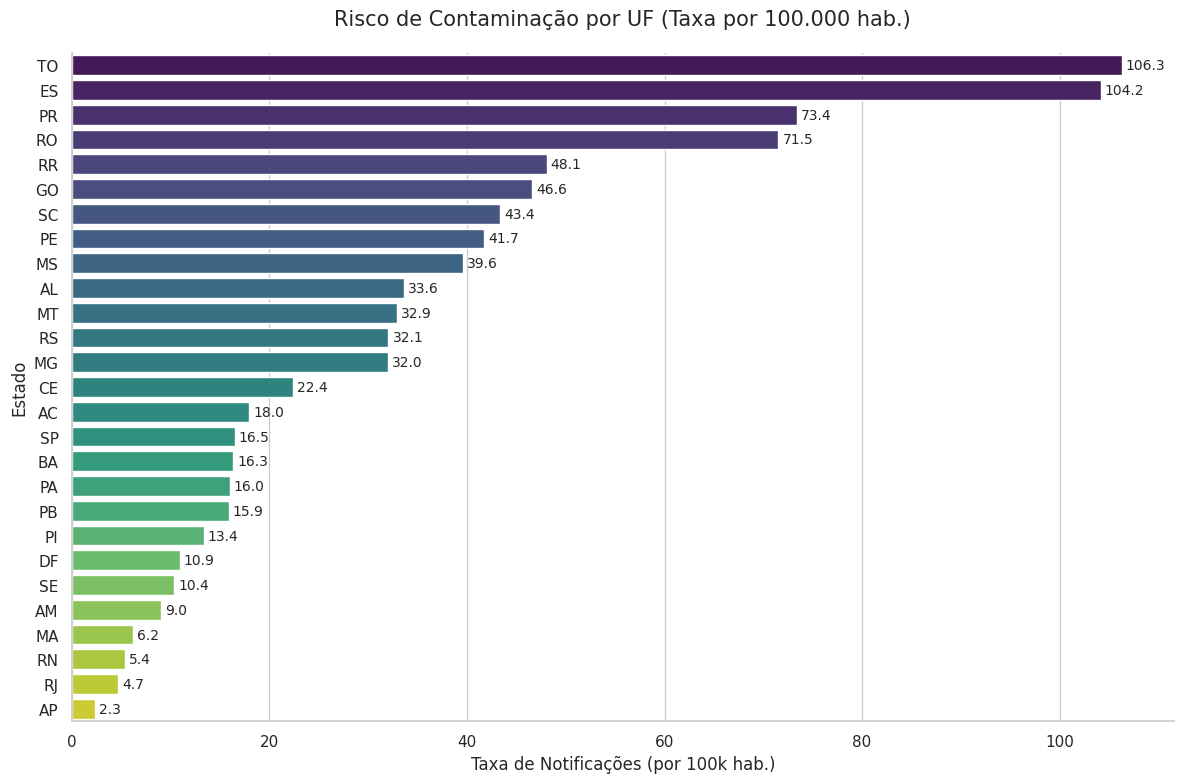

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Mapeamento oficial do IBGE para as Unidades da Federação
dic_uf = {
    11: 'RO', 12: 'AC', 13: 'AM', 14: 'RR', 15: 'PA', 16: 'AP', 17: 'TO',
    21: 'MA', 22: 'PI', 23: 'CE', 24: 'RN', 25: 'PB', 26: 'PE', 27: 'AL', 28: 'SE', 29: 'BA',
    31: 'MG', 32: 'ES', 33: 'RJ', 35: 'SP',
    41: 'PR', 42: 'SC', 43: 'RS',
    50: 'MS', 51: 'MT', 52: 'GO', 53: 'DF'
}

# População do Censo 2022 por UF (IBGE)
pop_uf_2022 = {
    'SP': 44411238, 'MG': 20538718, 'RJ': 16054524, 'BA': 14141626,
    'PR': 11444380, 'RS': 10882965, 'PE': 9058931, 'CE': 8794957,
    'PA': 8121025, 'SC': 7610361, 'GO': 7056495, 'MA': 6775805,
    'PB': 3974687, 'AM': 3941613, 'ES': 3833712, 'MT': 3658649,
    'RN': 3302729, 'PI': 3271199, 'AL': 3127683, 'DF': 2817381,
    'MS': 2757013, 'SE': 2209558, 'RO': 1581196, 'TO': 1511460,
    'AC': 830018, 'AP': 733759, 'RR': 636707
}

# 1. Converte e mapeia o código da UF
df_ag['UF_NOME'] = df_ag['UF_EMP'].astype(float).fillna(0).astype(int).map(dic_uf)

# 2. Calcula a frequência (casos absolutos)
contagem_uf = df_ag['UF_NOME'].value_counts().reset_index()
contagem_uf.columns = ['Estado', 'Casos']

# 3. NOVO: Mapeia a população e calcula a taxa por 100k
contagem_uf['Populacao'] = contagem_uf['Estado'].map(pop_uf_2022)
contagem_uf['Taxa_100k'] = (contagem_uf['Casos'] / contagem_uf['Populacao']) * 100000

# Ordena da maior taxa para a menor para o gráfico de barras
contagem_uf = contagem_uf.sort_values(by='Taxa_100k', ascending=False)

# 4. Criação do Gráfico
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=contagem_uf,
    x='Taxa_100k', # Alterado para plotar a taxa
    y='Estado',
    palette='viridis',
    hue='Estado',
    legend=False
)

# Adiciona os valores nas pontas das barras (formatado para 1 casa decimal)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=10)

plt.title('Risco de Contaminação por UF (Taxa por 100.000 hab.)', fontsize=15, pad=20)
plt.xlabel('Taxa de Notificações (por 100k hab.)', fontsize=12)
plt.ylabel('Estado', fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()

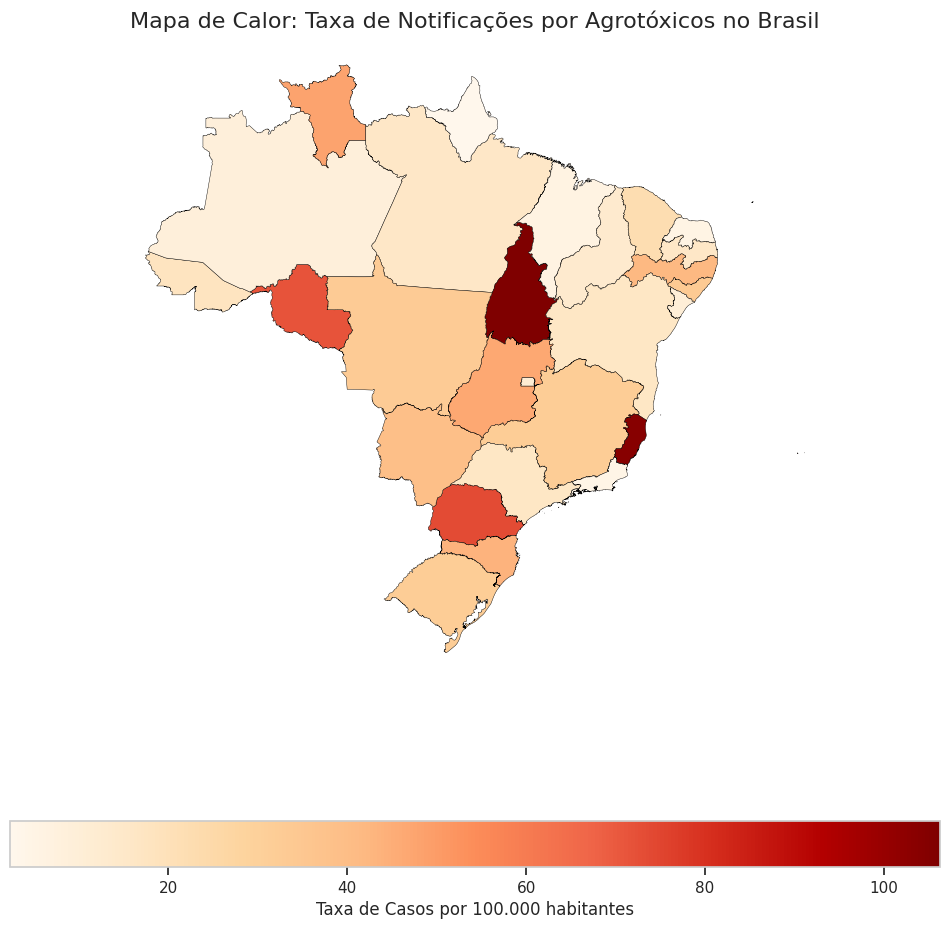

In [45]:
import geopandas as gpd
import geobr
import matplotlib.pyplot as plt

# 1. Baixa os mapas das UFs do Brasil (IBGE)
mapa_brasil = geobr.read_state(year=2020)

# 2. Une os dados de contaminação com o mapa
# 'abbrev_state' é a coluna de siglas no geobr
df_mapa = mapa_brasil.merge(contagem_uf, left_on='abbrev_state', right_on='Estado')

# 3. Plotagem
fig, ax = plt.subplots(1, 1, figsize=(12, 12))
df_mapa.plot(
    column='Taxa_100k', # Mudança principal: o mapa agora pinta baseado na taxa
    cmap='OrRd',
    legend=True,
    legend_kwds={'label': "Taxa de Casos por 100.000 habitantes", 'orientation': "horizontal"},
    ax=ax,
    edgecolor='black',
    linewidth=0.3
)

ax.set_title('Mapa de Calor: Taxa de Notificações por Agrotóxicos no Brasil', fontsize=16)
ax.axis('off') # Remove as coordenadas de latitude/longitude
plt.show()